In [1]:
import torch
import os
import sys

os.environ["GEOMSTATS_BACKEND"] = "pytorch"
os.environ["SCIPY_ARRAY_API"] = "1"

import numpy as np
import matplotlib.pyplot as plt

from sklearn import datasets
from sklearn.decomposition import PCA
from matplotlib.lines import Line2D
from geomstats.geometry.grassmannian import Grassmannian
from geomstats.learning.pca import TangentPCA

from xp_datasets import get_plot_kde_grassmann, plot_projections
from xp_datasets import annotate_outlier

sys.path.append("../")
from lib_pca.lifted_pca import LiftedPCA
from lib_pca.uncertainty_aware_pca import UAPCA
from lib_pca.utils_kde import kde_stiefel
from lib_pca.utils_plot import plot_gaussian_kde

[KeOps] Warning : CUDA libraries not found or could not be loaded; Switching to CPU only.


In [2]:
iris = datasets.load_iris()
X = iris.data
labels = iris.target

print(X.shape, len(np.unique(labels)))

(150, 4) 3


## PCA

In [3]:
## PCA

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X)

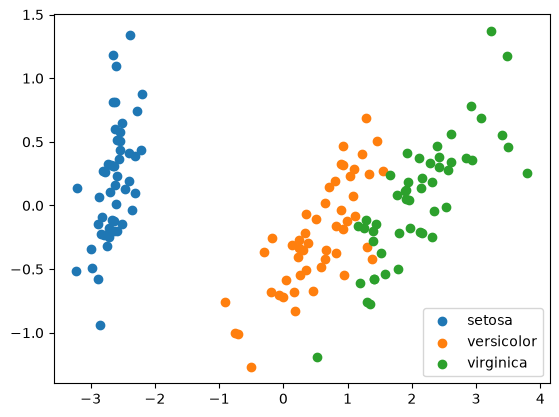

In [4]:
for k in range(3):
    plt.scatter(X_reduced[labels==k, 0], X_reduced[labels==k, 1], label=iris.target_names[k])

plt.legend()
plt.show()

## UAPCA

In [ ]:
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

# Distributional PCA
pca_distributional = UAPCA(2)
pca_distributional.fit_from_samples(samples_iris)
eigenvectors_distributional = pca_distributional.components_# .numpy()
print("Barycenter cost:", pca_distributional.cost_barycenter(samples_iris).item())

INFO:2026-10-13 21:44:34,751:jax._src.xla_bridge:812: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
INFO: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory


Barycenter cost: 0.1013648653865369


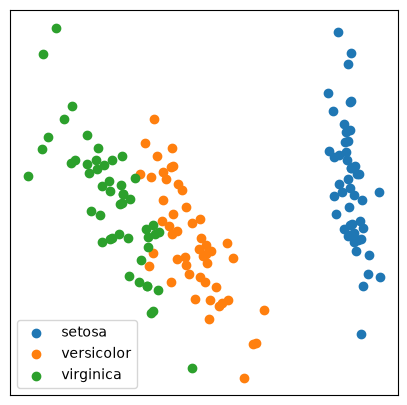

In [6]:
fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", pca_distributional.components_, torch.from_numpy(X)).numpy()
for k in range(3):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

## Lifted PCA

In [7]:
# Fix the weights and optim over support only
samples_iris = [torch.from_numpy(X[iris.target==k]) for k in range(3)]

lifted_pca = LiftedPCA(n_components=2, n_samples=100)
lifted_pca.fit(samples_iris)
eigenvectors_lifted = lifted_pca.components_

print("Barycenter cost:", lifted_pca.cost_barycenter(samples_iris).item())

Barycenter cost: 0.001792177610195757


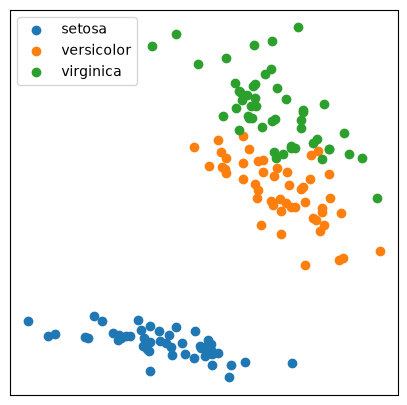

In [8]:
U_bary = lifted_pca.get_barycenter_components()

fig, ax = plt.subplots(
    nrows=1, 
    ncols=1,
    figsize=(5,5)
)

proj_points = torch.einsum("ij, ki -> kj", U_bary, torch.from_numpy(X)).numpy()
for k in range(3):
    ax.scatter(proj_points[labels == k, 0], proj_points[labels == k, 1], label=iris.target_names[k]) # , alpha=alpha[i*10+j])

ax.legend()

ax.set_xticks([])
ax.set_yticks([])

plt.show()

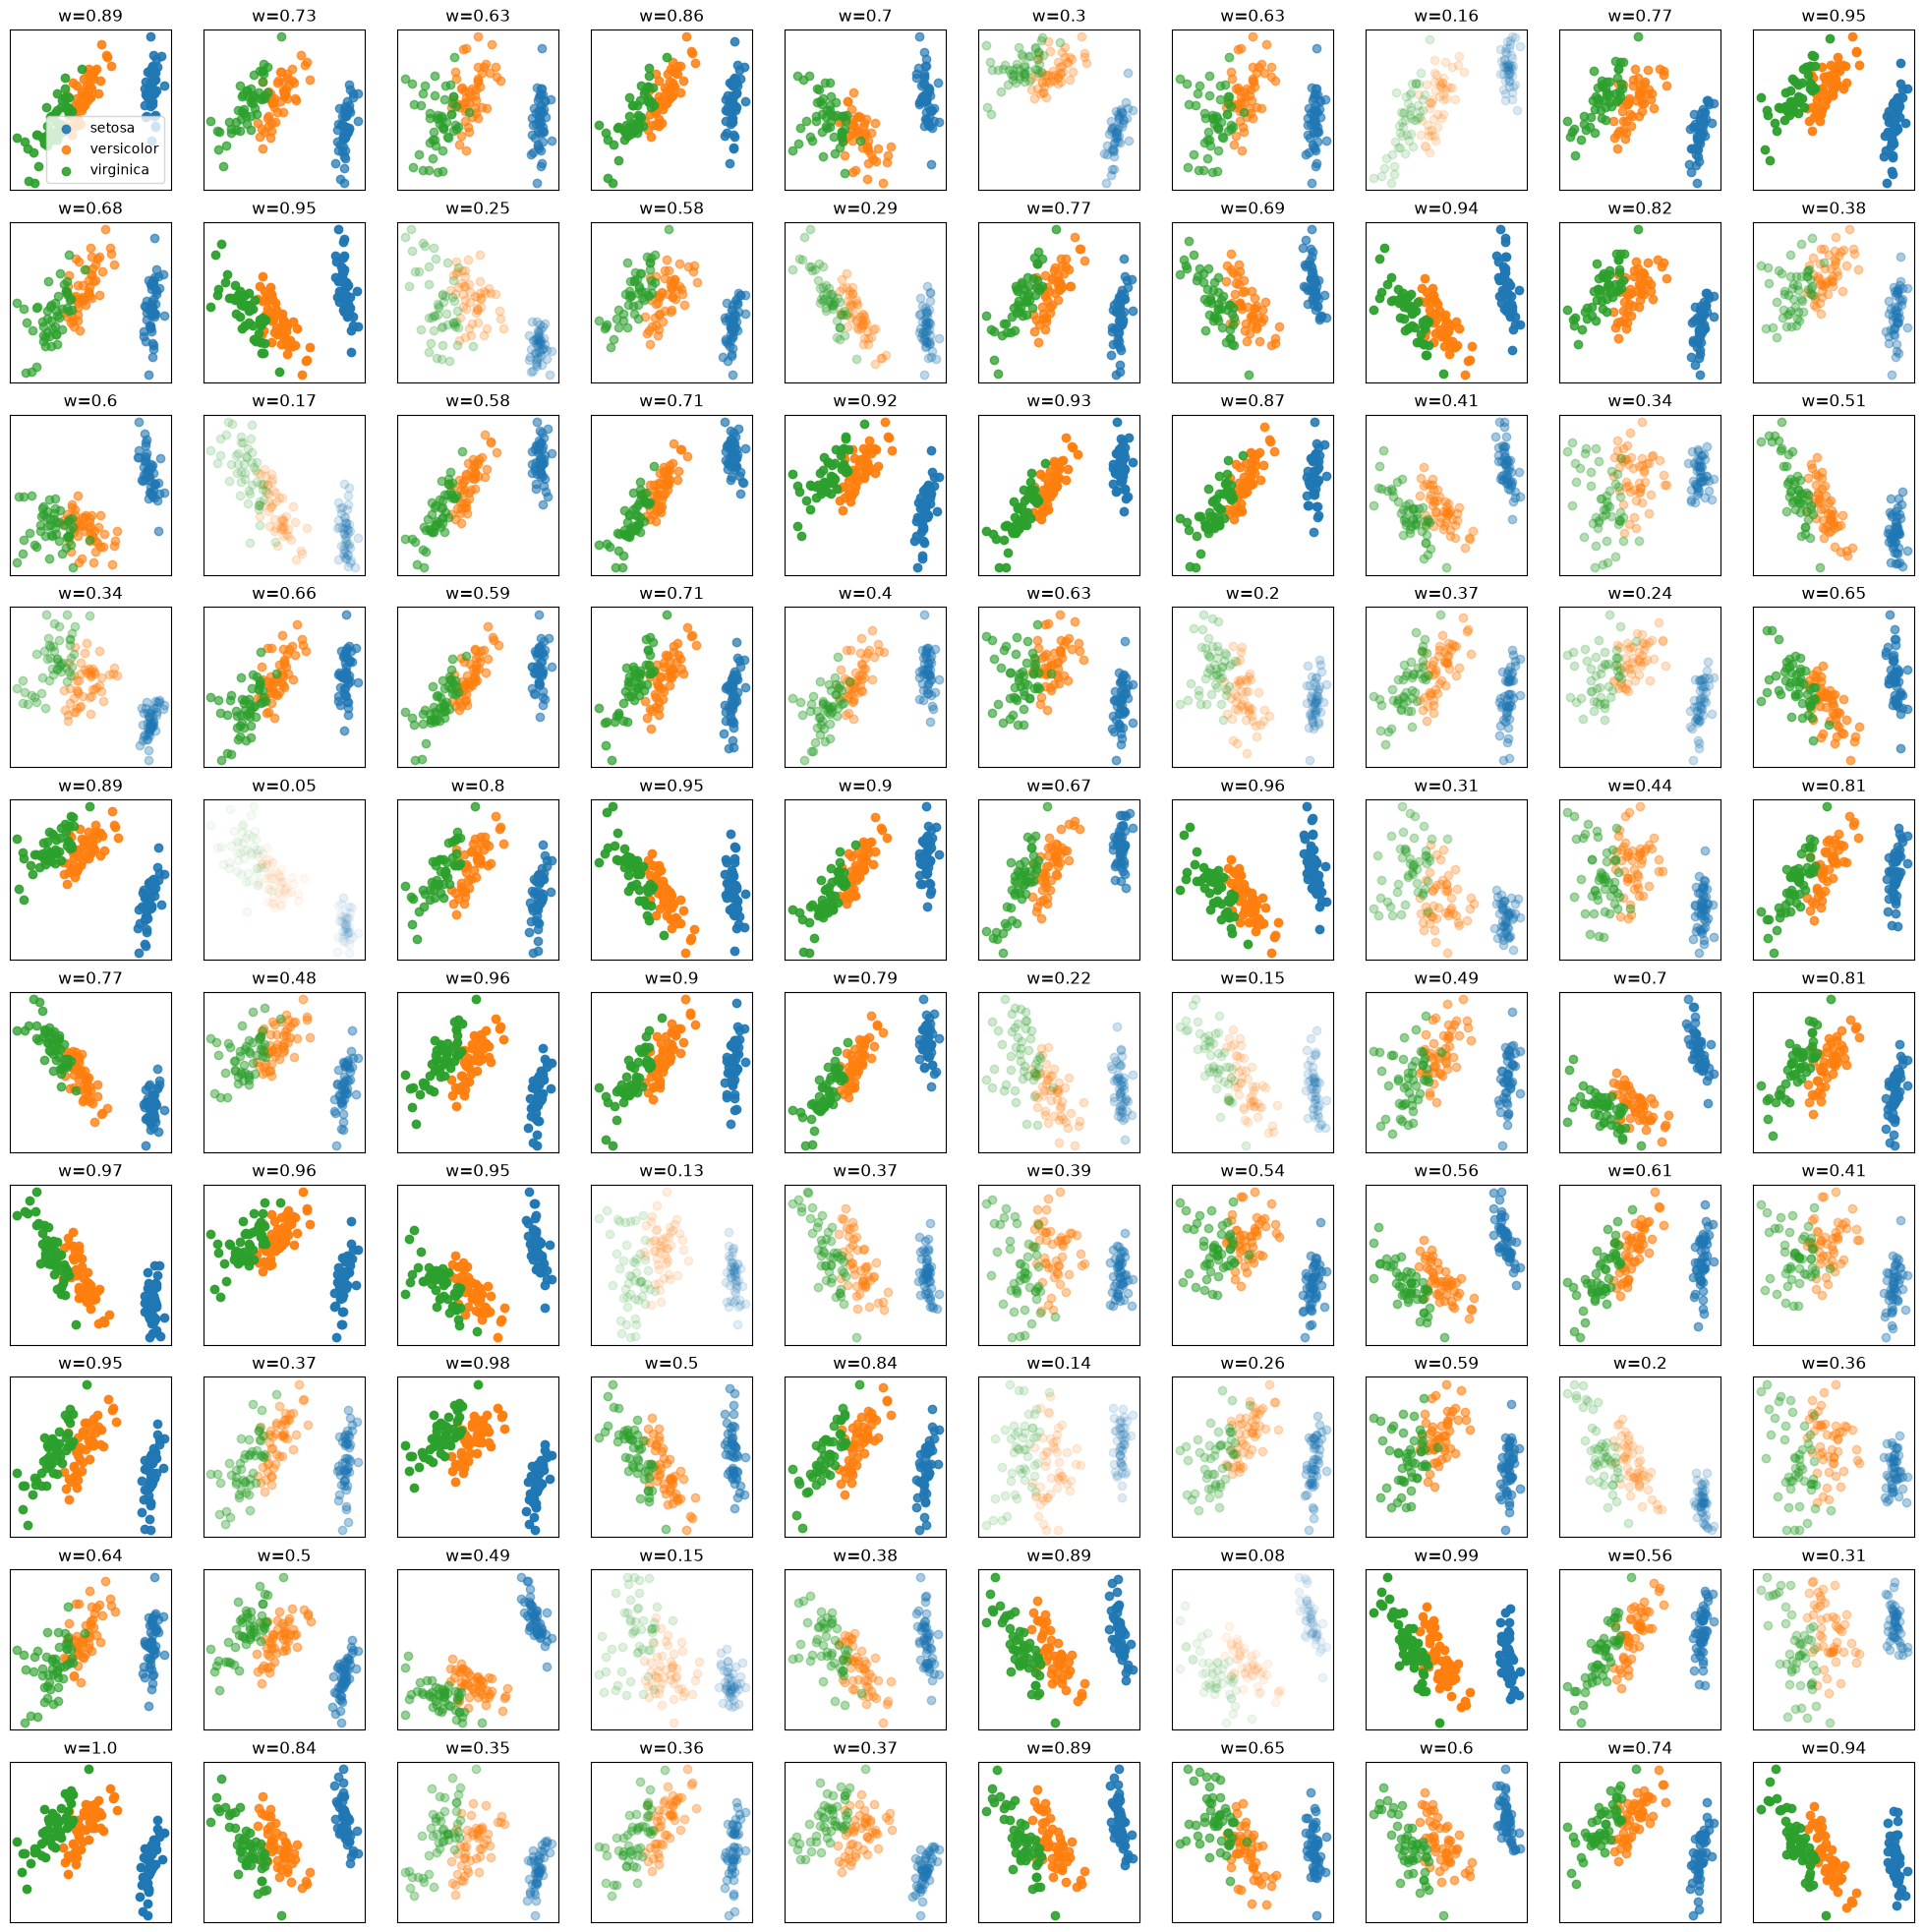

In [9]:
# weights = lifted_pca.weights_.numpy()
weights = kde_stiefel(lifted_pca.components_, lifted_pca.components_, 0.25).numpy()
min_weights = weights.min()
max_weights = weights.max()
diff = max_weights - min_weights
alpha = 0.05 + 0.95 * (weights - min_weights) / diff

fig, axes = plt.subplots(
    nrows=10, 
    ncols=10,
    figsize=(25,25)
)

for i in range(10):
    for j in range(10):
        U = lifted_pca.components_[i*10+j]
        proj_points = torch.einsum("ij, ki -> kj", U, torch.from_numpy(X)).numpy()
        for k in range(3):
            axes[i, j].scatter(proj_points[iris.target == k, 0], proj_points[iris.target == k, 1], label=iris.target_names[k] , alpha=alpha[i*10+j])

        if i == 0 and j == 0:
            axes[i, j].legend()

        axes[i, j].set_xticks([])
        axes[i, j].set_yticks([])

        axes[i, j].set_title("w=" + str(round(alpha[i*10+j], 2)))

plt.show()

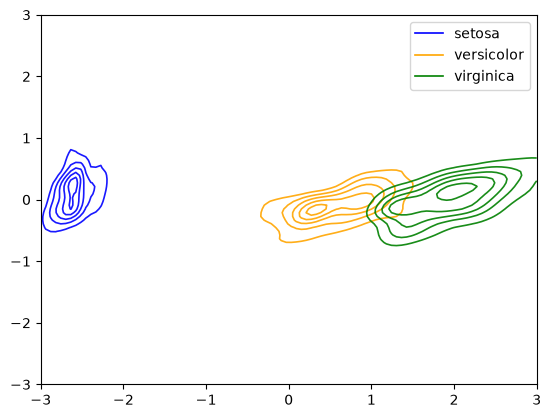

In [10]:
## KDE on PCA of projections

centered_samples = lifted_pca.center_data(samples_iris)

L_projected_samples = []
for k in range(len(centered_samples)):
    projected_samples = lifted_pca.project_samples(centered_samples[k]).reshape(-1, 4)
    L_projected_samples.append(projected_samples)

full_projected_samples = torch.stack(L_projected_samples).reshape(-1, 4)

pca = PCA(2)
projected_samples_2D = pca.fit_transform(full_projected_samples)


palette = ["blue", "orange", "green"]

legend_handles = []

for k in range(len(centered_samples)):
    plot_gaussian_kde(projected_samples_2D[k*5000: (k+1)*5000], color=palette[k])

    legend_handles.append(Line2D([0], [0], color=palette[k], lw=1.2, label=iris.target_names[k]))


plt.legend(handles=legend_handles)


plt.show()

In [11]:
# get_plot_kde_grassmann(lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces")

In [12]:
# proj_low, proj_top, _, _, _ = get_plot_kde_grassmann(lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces", get_outliers=True)

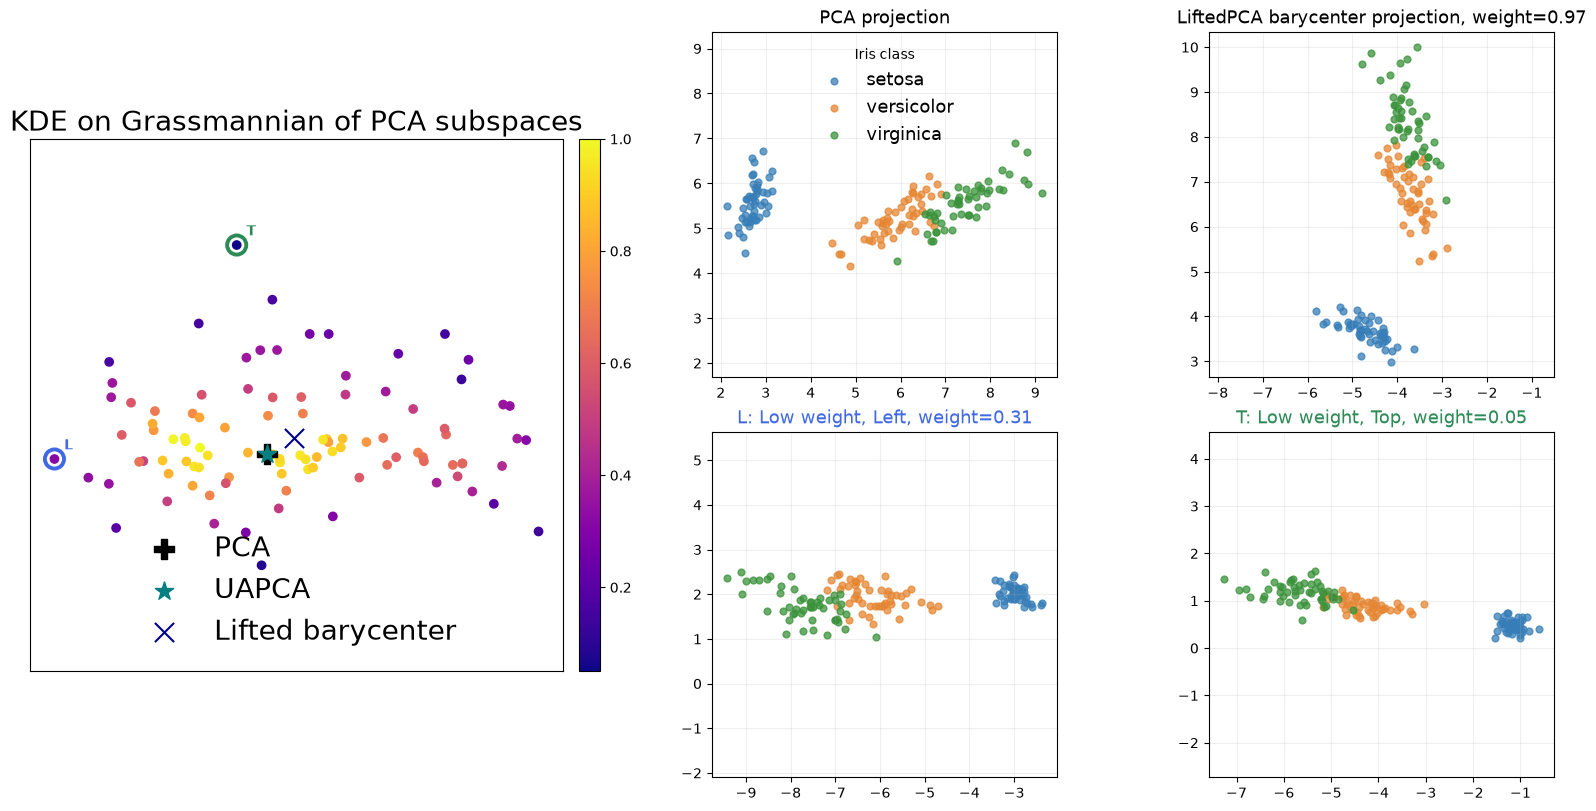

In [ ]:
fig = plt.figure(figsize=(16, 8), constrained_layout=True)

outer_grid = fig.add_gridspec(1, 2, width_ratios=[1.35, 2.5])

projection_grid = outer_grid[1].subgridspec(2, 2)

ax_weights = fig.add_subplot(outer_grid[0])
ax_pca = fig.add_subplot(projection_grid[0, 0])
ax_barycenter = fig.add_subplot(projection_grid[0, 1])
ax_left_low = fig.add_subplot(projection_grid[1, 0])
ax_top_low = fig.add_subplot(projection_grid[1, 1])

pca_grassmann, alpha, alpha_bary = get_plot_kde_grassmann(
    lifted_pca, pca=pca_distributional, uapca=pca_distributional, title="KDE on Grassmannian of PCA subspaces", ax=ax_weights, fontsize=20
)

tangent_projected_data = pca_grassmann.transform(lifted_pca.components_).detach().cpu().numpy()
low_candidates = np.argsort(alpha)[:max(2, int(np.ceil(0.2 * len(alpha))))]
left_low_idx = int(low_candidates[np.argmin(tangent_projected_data[low_candidates, 0])])
top_candidates = low_candidates[low_candidates != left_low_idx]
top_low_idx = int(top_candidates[np.argmax(tangent_projected_data[top_candidates, 1])])

annotate_outlier(ax_weights, tangent_projected_data[left_low_idx], marker_color="royalblue", label="L")
annotate_outlier(ax_weights, tangent_projected_data[top_low_idx], marker_color="seagreen", label="T")

proj_low = lifted_pca.components_[left_low_idx]
proj_top = lifted_pca.components_[top_low_idx]
alpha_low, alpha_top, alpha_bary = alpha[left_low_idx], alpha[top_low_idx], alpha_bary[0]

X_torch = torch.as_tensor(
    X, dtype=lifted_pca.components_.dtype, device=lifted_pca.components_.device
)
class_colors = ["#377eb8", "#e68632", "#3a923a"]

plot_projections(X_torch, pca.components_.T, iris.target, iris.target_names, ax=ax_pca, title="PCA projection", colors=class_colors)
plot_projections(X_torch, lifted_pca.get_barycenter_components(), iris.target, iris.target_names, ax=ax_barycenter,
                 title=f"LiftedPCA barycenter projection, weight={alpha_bary:.2f}", colors=class_colors)

plot_projections(X_torch, proj_low, iris.target, iris.target_names, ax=ax_left_low,
                 title=f"L: Low weight, Left, weight={alpha_low:.2f}", title_color="royalblue", colors=class_colors)

plot_projections(X_torch, proj_top, iris.target, iris.target_names, ax=ax_top_low,
                 title=f"T: Low weight, Top, weight={alpha_top:.2f}", title_color="seagreen", colors=class_colors)

ax_pca.legend(title="Iris class", frameon=False, fontsize=13)

# plt.savefig("./Figures/Results_iris.pdf", format="pdf", bbox_inches="tight")
plt.show()